In [1]:
# ============================================================
# NLP - SYMPTOM TO DISEASE CLASSIFICATION
# INITIAL SETUP
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATA_PATH = "../datasets/nlp/symptom2disease/Symptom2Disease.csv"

df_nlp = pd.read_csv(DATA_PATH)

print("=" * 70)
print("NLP DATASET LOADED SUCCESSFULLY")
print("=" * 70)

print(f"Rows: {df_nlp.shape[0]}")
print(f"Columns: {df_nlp.shape[1]}")

print("\nColumns:")
print(df_nlp.columns.tolist())

NLP DATASET LOADED SUCCESSFULLY
Rows: 1200
Columns: 3

Columns:
['Unnamed: 0', 'label', 'text']


In [2]:
# ============================================================
# NLP - INITIAL DATA INSPECTION
# ============================================================

print("=" * 70)
print("DATASET INFO")
print("=" * 70)

print(df_nlp.info())

print("\n" + "=" * 70)
print("FIRST 10 RECORDS")
print("=" * 70)

display(df_nlp.head(10))

print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

print(df_nlp.isnull().sum())

print("\n" + "=" * 70)
print("DUPLICATE ROWS")
print("=" * 70)

print("Duplicate rows:", df_nlp.duplicated().sum())

print("\n" + "=" * 70)
print("DUPLICATE TEXTS")
print("=" * 70)

print("Duplicate texts:", df_nlp["text"].duplicated().sum())

print("\n" + "=" * 70)
print("NUMBER OF DISEASE CLASSES")
print("=" * 70)

print("Unique diseases:", df_nlp["label"].nunique())

print("\n" + "=" * 70)
print("DISEASE DISTRIBUTION")
print("=" * 70)

print(df_nlp["label"].value_counts())

print("\n" + "=" * 70)
print("DISEASE DISTRIBUTION (%)")
print("=" * 70)

print(
    (df_nlp["label"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\n" + "=" * 70)
print("TEXT LENGTH STATISTICS")
print("=" * 70)

df_nlp["text_length"] = df_nlp["text"].str.len()

print(df_nlp["text_length"].describe())

DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  1200 non-null   int64 
 1   label       1200 non-null   object
 2   text        1200 non-null   object
dtypes: int64(1), object(2)
memory usage: 28.2+ KB
None

FIRST 10 RECORDS


,Unnamed: 0,label,text
0,0,Psoriasis,I have been experiencing a skin rash on my arm...
1,1,Psoriasis,"My skin has been peeling, especially on my kne..."
2,2,Psoriasis,I have been experiencing joint pain in my fing...
3,3,Psoriasis,"There is a silver like dusting on my skin, esp..."
4,4,Psoriasis,"My nails have small dents or pits in them, and..."
5,5,Psoriasis,The skin on my palms and soles is thickened an...
6,6,Psoriasis,"The skin around my mouth, nose, and eyes is re..."
7,7,Psoriasis,My skin is very sensitive and reacts easily to...
8,8,Psoriasis,I have noticed a sudden peeling of skin at dif...
9,9,Psoriasis,The skin on my genitals is red and inflamed. I...



MISSING VALUES
Unnamed: 0    0
label         0
text          0
dtype: int64

DUPLICATE ROWS
Duplicate rows: 0

DUPLICATE TEXTS
Duplicate texts: 47

NUMBER OF DISEASE CLASSES
Unique diseases: 24

DISEASE DISTRIBUTION
label
Psoriasis                          50
Varicose Veins                     50
Typhoid                            50
Chicken pox                        50
Impetigo                           50
Dengue                             50
Fungal infection                   50
Common Cold                        50
Pneumonia                          50
Dimorphic Hemorrhoids              50
Arthritis                          50
Acne                               50
Bronchial Asthma                   50
Hypertension                       50
Migraine                           50
Cervical spondylosis               50
Jaundice                           50
Malaria                            50
urinary tract infection            50
allergy                            50
gastroesophageal 

In [3]:
# ============================================================
# NLP - DUPLICATE TEXT CONFLICT ANALYSIS
# ============================================================

print("=" * 70)
print("DUPLICATE TEXT ANALYSIS")
print("=" * 70)

# Find texts that occur more than once
duplicate_texts = df_nlp[
    df_nlp["text"].duplicated(keep=False)
].sort_values("text")

print(f"Rows belonging to duplicate text groups: {len(duplicate_texts)}")
print(f"Unique duplicated texts: {duplicate_texts['text'].nunique()}")

# Check whether duplicated texts have multiple labels
text_label_counts = (
    duplicate_texts
    .groupby("text")["label"]
    .nunique()
)

conflicting_texts = text_label_counts[
    text_label_counts > 1
]

print("\nDuplicate texts with conflicting disease labels:")
print(len(conflicting_texts))

if len(conflicting_texts) > 0:
    print("\nExamples of conflicting texts:")
    display(
        duplicate_texts[
            duplicate_texts["text"].isin(conflicting_texts.index)
        ].head(20)
    )
else:
    print("No conflicting duplicate texts found.")

DUPLICATE TEXT ANALYSIS
Rows belonging to duplicate text groups: 90
Unique duplicated texts: 43

Duplicate texts with conflicting disease labels:
0
No conflicting duplicate texts found.


In [4]:
# ============================================================
# NLP - DATA CLEANING
# ============================================================

print("=" * 70)
print("NLP DATA CLEANING")
print("=" * 70)

# Remove index/metadata column
df_nlp_clean = df_nlp.drop(columns=["Unnamed: 0"]).copy()

# Remove temporary EDA column
if "text_length" in df_nlp_clean.columns:
    df_nlp_clean = df_nlp_clean.drop(columns=["text_length"])

print(f"Original rows: {len(df_nlp_clean)}")

# Remove duplicate symptom descriptions
df_nlp_clean = df_nlp_clean.drop_duplicates(
    subset=["text"],
    keep="first"
).reset_index(drop=True)

print(f"Rows after duplicate-text removal: {len(df_nlp_clean)}")
print(f"Rows removed: {1200 - len(df_nlp_clean)}")

print("\nFinal columns:")
print(df_nlp_clean.columns.tolist())

print("\nFinal class distribution:")
print(df_nlp_clean["label"].value_counts())

NLP DATA CLEANING
Original rows: 1200
Rows after duplicate-text removal: 1153
Rows removed: 47

Final columns:
['label', 'text']

Final class distribution:
label
Psoriasis                          50
Varicose Veins                     50
Typhoid                            50
Impetigo                           50
Fungal infection                   50
Dengue                             50
peptic ulcer disease               50
Hypertension                       50
drug reaction                      50
allergy                            50
urinary tract infection            50
diabetes                           50
Common Cold                        49
Chicken pox                        49
Cervical spondylosis               49
Bronchial Asthma                   49
gastroesophageal reflux disease    48
Pneumonia                          47
Migraine                           47
Arthritis                          46
Acne                               46
Malaria                            44
Di

In [5]:
# ============================================================
# NLP - TEXT CHARACTERISTICS
# ============================================================

df_nlp_clean["word_count"] = (
    df_nlp_clean["text"]
    .str.split()
    .str.len()
)

df_nlp_clean["char_count"] = (
    df_nlp_clean["text"]
    .str.len()
)

print("=" * 70)
print("TEXT LENGTH STATISTICS")
print("=" * 70)

display(
    df_nlp_clean[["word_count", "char_count"]].describe()
)

print("\n" + "=" * 70)
print("SAMPLE SYMPTOM DESCRIPTIONS")
print("=" * 70)

display(
    df_nlp_clean[["label", "text"]]
    .sample(10, random_state=42)
)

print("\n" + "=" * 70)
print("SHORTEST TEXTS")
print("=" * 70)

display(
    df_nlp_clean
    .sort_values("word_count")
    [["label", "text", "word_count"]]
    .head(5)
)

print("\n" + "=" * 70)
print("LONGEST TEXTS")
print("=" * 70)

display(
    df_nlp_clean
    .sort_values("word_count", ascending=False)
    [["label", "text", "word_count"]]
    .head(5)
)

TEXT LENGTH STATISTICS


,word_count,char_count
count,1153.000000,1153.000000
mean,30.625325,171.112749
std,6.717653,35.500946
min,12.000000,60.000000
25%,26.000000,147.000000
50%,30.000000,169.000000
75%,35.000000,192.000000
max,55.000000,317.000000



SAMPLE SYMPTOM DESCRIPTIONS


,label,text
767,Cervical spondylosis,"I've had back pain, a cough that won't go away..."
461,Dimorphic Hemorrhoids,"Recently, I've been having problems using the ..."
787,Jaundice,I've been exhausted and experiencing nausea an...
593,Bronchial Asthma,"I've had a nagging cough that won't go away, a..."
388,Common Cold,I've been quite exhausted and ill. My throat h...
1030,drug reaction,"My body itches all over, and I have rashes on ..."
199,Impetigo,I have developed a skin rash on my face and ne...
813,Malaria,"Strong itchiness, chills, nausea, and a high t..."
308,Fungal infection,"On my arms and legs, I have a lot of red pimpl..."
439,Pneumonia,I'm drenched with sweat and can't seem to catc...



SHORTEST TEXTS


,label,text,word_count
871,urinary tract infection,I have been having pain in my bladder and have...,12
681,Migraine,"I've been facing visual disruptions, seeing th...",12
680,Migraine,"I've been suffering visual disruptions, seeing...",12
636,Hypertension,"My symptoms include a headache, chest pain, di...",14
689,Migraine,In addition to having a stiff neck and eye iss...,15



LONGEST TEXTS


,label,text,word_count
596,Bronchial Asthma,I've had this cough that's been lingering for ...,55
368,Common Cold,"My eyes are always red and itchy, and my nose ...",53
597,Bronchial Asthma,"I've had a persistent cough for days, and I al...",51
371,Common Cold,My eyes are red and watery all the time. I've ...,50
324,Fungal infection,"I have a lot of itching all over my skin, and ...",50


In [6]:
# ============================================================
# NLP - TRAIN / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Features and target
X = df_nlp_clean["text"]
y = df_nlp_clean["label"]

# Stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 70)
print("NLP TRAIN / TEST SPLIT")
print("=" * 70)

print(f"Total samples   : {len(X)}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples : {len(X_test)}")

print("\nNumber of disease classes:")
print(f"Training: {y_train.nunique()}")
print(f"Testing : {y_test.nunique()}")

print("\n" + "=" * 70)
print("TRAINING CLASS DISTRIBUTION")
print("=" * 70)

print(y_train.value_counts().sort_index())

print("\n" + "=" * 70)
print("TEST CLASS DISTRIBUTION")
print("=" * 70)

print(y_test.value_counts().sort_index())

NLP TRAIN / TEST SPLIT
Total samples   : 1153
Training samples: 922
Testing samples : 231

Number of disease classes:
Training: 24
Testing : 24

TRAINING CLASS DISTRIBUTION
label
Acne                               37
Arthritis                          37
Bronchial Asthma                   39
Cervical spondylosis               39
Chicken pox                        39
Common Cold                        39
Dengue                             40
Dimorphic Hemorrhoids              33
Fungal infection                   40
Hypertension                       40
Impetigo                           40
Jaundice                           30
Malaria                            35
Migraine                           38
Pneumonia                          38
Psoriasis                          40
Typhoid                            40
Varicose Veins                     40
allergy                            40
diabetes                           40
drug reaction                      40
gastroesophageal reflux

In [7]:
# ============================================================
# NLP - TF-IDF FEATURE EXTRACTION
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Fit ONLY on training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# Transform test data using the same fitted vectorizer
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("=" * 70)
print("TF-IDF FEATURE EXTRACTION")
print("=" * 70)

print(f"Training samples : {X_train_tfidf.shape[0]}")
print(f"Testing samples  : {X_test_tfidf.shape[0]}")
print(f"TF-IDF features  : {X_train_tfidf.shape[1]}")

print("\nTraining matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape :", X_test_tfidf.shape)

print("\nMatrix type:", type(X_train_tfidf).__name__)
print("Matrix density:",
      round(
          X_train_tfidf.nnz /
          (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]) * 100,
          4
      ),
      "%")

TF-IDF FEATURE EXTRACTION
Training samples : 922
Testing samples  : 231
TF-IDF features  : 2901

Training matrix shape: (922, 2901)
Testing matrix shape : (231, 2901)

Matrix type: csr_matrix
Matrix density: 0.772 %


In [8]:
# ============================================================
# NLP - MODEL CREATION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# Logistic Regression
logistic_nlp = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Linear Support Vector Machine
svm_nlp = LinearSVC(
    random_state=42
)

# Multinomial Naive Bayes
nb_nlp = MultinomialNB()

print("=" * 70)
print("NLP CLASSIFICATION MODELS CREATED")
print("=" * 70)

print("Logistic Regression model created.")
print("Linear SVM model created.")
print("Multinomial Naive Bayes model created.")

NLP CLASSIFICATION MODELS CREATED
Logistic Regression model created.
Linear SVM model created.
Multinomial Naive Bayes model created.


In [9]:
# ============================================================
# NLP - TRAINING: LOGISTIC REGRESSION
# ============================================================

import time

print("=" * 70)
print("TRAINING: LOGISTIC REGRESSION")
print("=" * 70)

start_time = time.time()

logistic_nlp.fit(X_train_tfidf, y_train)

lr_training_time = time.time() - start_time

print("\nTraining completed successfully.")
print(f"Training time: {lr_training_time:.2f} seconds")

TRAINING: LOGISTIC REGRESSION

Training completed successfully.
Training time: 0.16 seconds


In [10]:
# ============================================================
# NLP - EVALUATION: LOGISTIC REGRESSION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("EVALUATION: LOGISTIC REGRESSION")
print("=" * 70)

# Predictions
y_pred_lr = logistic_nlp.predict(X_test_tfidf)

# Metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(
    y_test,
    y_pred_lr,
    average="weighted",
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    y_pred_lr,
    average="weighted",
    zero_division=0
)

lr_f1 = f1_score(
    y_test,
    y_pred_lr,
    average="weighted",
    zero_division=0
)

print(f"\nAccuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1 Score  : {lr_f1:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

# Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        zero_division=0
    )
)

EVALUATION: LOGISTIC REGRESSION

Accuracy  : 0.9524
Precision : 0.9553
Recall    : 0.9524
F1 Score  : 0.9520

Confusion Matrix:
[[ 9  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  9  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  9  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  0  8  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  8  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  8  0  0  0 

In [11]:
# ============================================================
# NLP - TRAINING: LINEAR SVM
# ============================================================

import time

print("=" * 70)
print("TRAINING: LINEAR SVM")
print("=" * 70)

start_time = time.time()

svm_nlp.fit(X_train_tfidf, y_train)

svm_training_time = time.time() - start_time

print("\nTraining completed successfully.")
print(f"Training time: {svm_training_time:.2f} seconds")

TRAINING: LINEAR SVM

Training completed successfully.
Training time: 0.05 seconds


In [12]:
# ============================================================
# NLP - EVALUATION: LINEAR SVM
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("EVALUATION: LINEAR SVM")
print("=" * 70)

# Predictions
y_pred_svm = svm_nlp.predict(X_test_tfidf)

# Metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_precision = precision_score(
    y_test,
    y_pred_svm,
    average="weighted",
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    y_pred_svm,
    average="weighted",
    zero_division=0
)

svm_f1 = f1_score(
    y_test,
    y_pred_svm,
    average="weighted",
    zero_division=0
)

print(f"\nAccuracy  : {svm_accuracy:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1 Score  : {svm_f1:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

# Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        zero_division=0
    )
)

EVALUATION: LINEAR SVM

Accuracy  : 0.9481
Precision : 0.9522
Recall    : 0.9481
F1 Score  : 0.9475

Confusion Matrix:
[[ 9  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  9  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  9  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  0  8  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  8  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  8  0  0  0  0  0  0 

In [13]:
# ============================================================
# NLP - TRAINING: MULTINOMIAL NAIVE BAYES
# ============================================================

import time

print("=" * 70)
print("TRAINING: MULTINOMIAL NAIVE BAYES")
print("=" * 70)

start_time = time.time()

nb_nlp.fit(X_train_tfidf, y_train)

nb_training_time = time.time() - start_time

print("\nTraining completed successfully.")
print(f"Training time: {nb_training_time:.2f} seconds")

TRAINING: MULTINOMIAL NAIVE BAYES

Training completed successfully.
Training time: 0.00 seconds


In [14]:
# ============================================================
# NLP - EVALUATION: MULTINOMIAL NAIVE BAYES
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("EVALUATION: MULTINOMIAL NAIVE BAYES")
print("=" * 70)

# Predictions
y_pred_nb = nb_nlp.predict(X_test_tfidf)

# Metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_precision = precision_score(
    y_test,
    y_pred_nb,
    average="weighted",
    zero_division=0
)

nb_recall = recall_score(
    y_test,
    y_pred_nb,
    average="weighted",
    zero_division=0
)

nb_f1 = f1_score(
    y_test,
    y_pred_nb,
    average="weighted",
    zero_division=0
)

print(f"\nAccuracy  : {nb_accuracy:.4f}")
print(f"Precision : {nb_precision:.4f}")
print(f"Recall    : {nb_recall:.4f}")
print(f"F1 Score  : {nb_f1:.4f}")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

# Classification Report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_nb,
        zero_division=0
    )
)

EVALUATION: MULTINOMIAL NAIVE BAYES

Accuracy  : 0.9394
Precision : 0.9442
Recall    : 0.9394
F1 Score  : 0.9386

Confusion Matrix:
[[ 9  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  9  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  8  0  1  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  1  0  7  0  0  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  8  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  8  0  0

In [15]:
# ============================================================
# NLP MODEL PERFORMANCE COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

nlp_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "Multinomial Naive Bayes"
    ],
    "Accuracy": [
        0.9524,
        0.9481,
        0.9394
    ],
    "Precision": [
        0.9553,
        0.9522,
        0.9442
    ],
    "Recall": [
        0.9524,
        0.9481,
        0.9394
    ],
    "F1 Score": [
        0.9520,
        0.9475,
        0.9386
    ]
})

print("=" * 70)
print("NLP MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(nlp_results.round(4))

NLP MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9524,0.9553,0.9524,0.9520
1,Linear SVM,0.9481,0.9522,0.9481,0.9475
2,Multinomial Naive Bayes,0.9394,0.9442,0.9394,0.9386


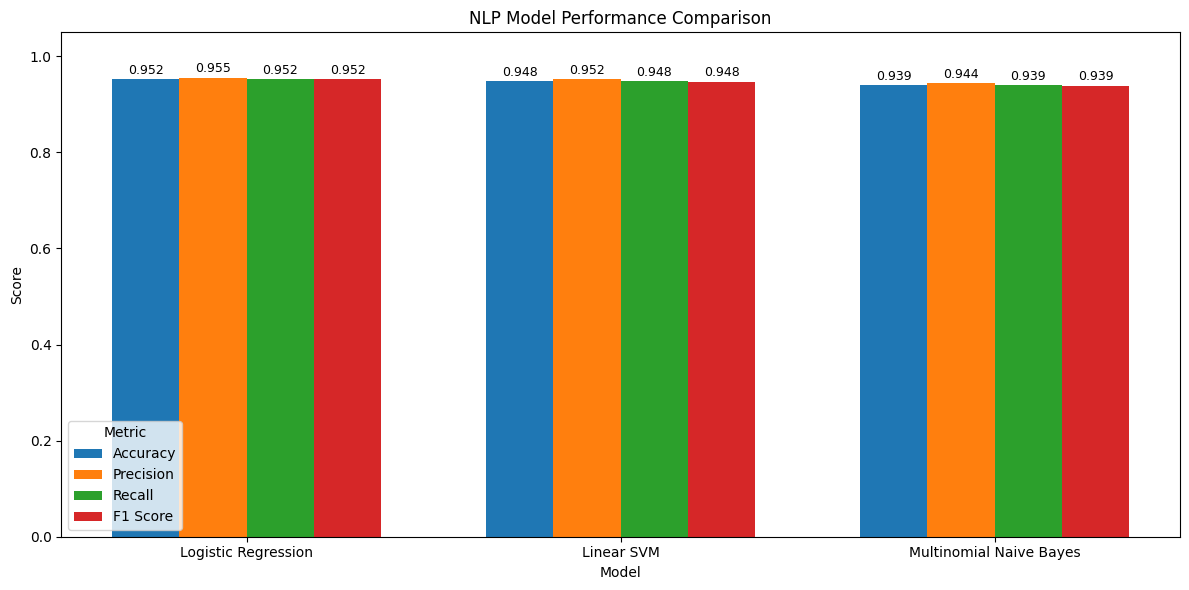

In [16]:
# ============================================================
# NLP MODEL PERFORMANCE VISUALIZATION
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

x = range(len(nlp_results["Model"]))
width = 0.18

plt.figure(figsize=(12, 6))

for i, metric in enumerate(metrics):
    values = nlp_results[metric]

    bars = plt.bar(
        [p + i * width for p in x],
        values,
        width=width,
        label=metric
    )

    # Display values on bars
    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.xlabel("Model")
plt.ylabel("Score")
plt.title("NLP Model Performance Comparison")

plt.xticks(
    [p + 1.5 * width for p in x],
    nlp_results["Model"]
)

plt.ylim(0, 1.05)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [18]:
# Show trained Logistic Regression objects currently in memory

from sklearn.linear_model import LogisticRegression

print("=" * 70)
print("LOGISTIC REGRESSION MODELS IN MEMORY")
print("=" * 70)

for name in list(globals().keys()):
    obj = globals()[name]

    if isinstance(obj, LogisticRegression):
        print(f"Variable: {name}")
        print(f"Classes: {len(obj.classes_)}")
        print(f"Coefficient shape: {obj.coef_.shape}")
        print()

LOGISTIC REGRESSION MODELS IN MEMORY
Variable: logistic_nlp
Classes: 24
Coefficient shape: (24, 2901)



In [19]:
# ============================================================
# TOP WORDS FOR EACH DISEASE
# ============================================================

TOP_N_WORDS = 15

# Get TF-IDF feature names
tfidf_features = tfidf_vectorizer.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = logistic_nlp.coef_

print("=" * 70)
print("TOP WORDS ASSOCIATED WITH EACH DISEASE")
print("=" * 70)

for class_index, disease in enumerate(logistic_nlp.classes_):

    class_coefficients = coefficients[class_index]

    # Highest positive coefficients
    top_indices = np.argsort(class_coefficients)[-TOP_N_WORDS:][::-1]

    top_words = tfidf_features[top_indices]

    print(f"\n{disease}")
    print("-" * 50)
    print(", ".join(top_words))

TOP WORDS ASSOCIATED WITH EACH DISEASE

Acne
--------------------------------------------------
pus, blackheads, pimples, filled, skin, filled pimples, pus filled, rash, pimples blackheads, scurrying, rash skin, blackheads skin, blackheads pimples, morning, blackheads pus

Arthritis
--------------------------------------------------
joints, walking, stiff, muscles, neck, difficult, weak, swollen, stiffness, joints swollen, walk, neck really, tight, uncomfortable, weak neck

Bronchial Asthma
--------------------------------------------------
cough, breathing, fever, mucoid, lot mucoid, ve coughing, coughing lot, coughing, high, sputum, mucoid sputum, ve, persistent cough, lot, mucus

Cervical spondylosis
--------------------------------------------------
neck hurts, neck, weakness, cough, hurts, pain, balance, arms legs, cough weakness, feet, bothering, dizziness, limb weakness, limb, weakness ve

Chicken pox
--------------------------------------------------
lost appetite, red, red spo

In [20]:
# ============================================================
# NLP - FEATURE IMPORTANCE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("TOP 20 NLP FEATURES BY LOGISTIC REGRESSION IMPORTANCE")
print("=" * 70)

# Get TF-IDF feature names
tfidf_features = tfidf_vectorizer.get_feature_names_out()

# Logistic Regression coefficients
coefficients = logistic_nlp.coef_

# Mean absolute coefficient across all 24 disease classes
mean_abs_coefficients = np.mean(
    np.abs(coefficients),
    axis=0
)

# Create importance dataframe
nlp_feature_importance = pd.DataFrame({
    "Feature": tfidf_features,
    "Importance": mean_abs_coefficients
})

# Sort by importance
nlp_feature_importance = (
    nlp_feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTOP 20 FEATURES")
print("-" * 70)

display(nlp_feature_importance.head(20))

TOP 20 NLP FEATURES BY LOGISTIC REGRESSION IMPORTANCE

TOP 20 FEATURES
----------------------------------------------------------------------


,Feature,Importance
0,skin,0.627096
1,fever,0.509848
2,pain,0.500898
3,throat,0.499582
4,chest,0.494225
5,ve,0.461472
6,neck,0.450416
7,cough,0.446947
8,headache,0.444822
9,lot,0.426228


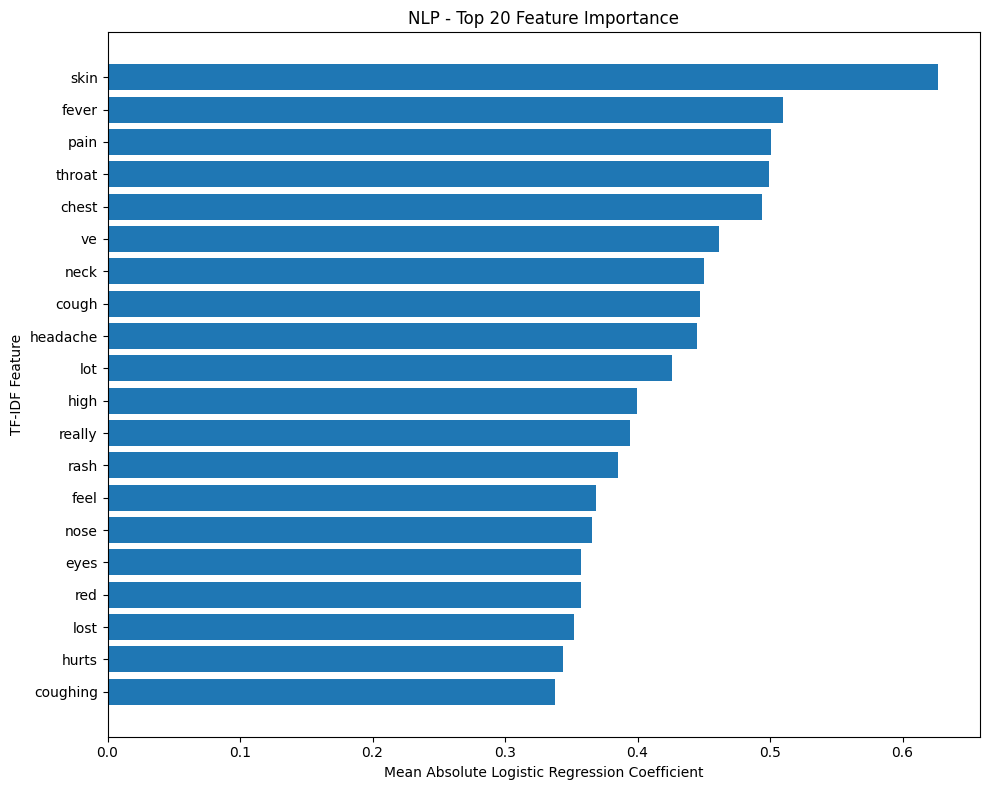

In [21]:
# ============================================================
# TOP 20 NLP FEATURE IMPORTANCE PLOT
# ============================================================

top_n = 20

top_features = nlp_feature_importance.head(top_n).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Mean Absolute Logistic Regression Coefficient")
plt.ylabel("TF-IDF Feature")
plt.title("NLP - Top 20 Feature Importance")

plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# SAVE FINAL NLP MODEL
# ============================================================

import os
import joblib

# Create model directory
MODEL_DIR = "../models/nlp"
os.makedirs(MODEL_DIR, exist_ok=True)

# Paths
NLP_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "clinical_disease_nlp_logistic_regression.joblib"
)

NLP_VECTORIZER_PATH = os.path.join(
    MODEL_DIR,
    "clinical_disease_tfidf_vectorizer.joblib"
)

# Save Logistic Regression model
joblib.dump(
    logistic_nlp,
    NLP_MODEL_PATH
)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf_vectorizer,
    NLP_VECTORIZER_PATH
)

print("=" * 70)
print("FINAL NLP MODEL SAVED")
print("=" * 70)

print(f"Model      : Logistic Regression")
print(f"Model path : {NLP_MODEL_PATH}")
print(f"Vectorizer : TF-IDF")
print(f"Vector path: {NLP_VECTORIZER_PATH}")

FINAL NLP MODEL SAVED
Model      : Logistic Regression
Model path : ../models/nlp\clinical_disease_nlp_logistic_regression.joblib
Vectorizer : TF-IDF
Vector path: ../models/nlp\clinical_disease_tfidf_vectorizer.joblib


In [23]:
# ============================================================
# VERIFY SAVED NLP MODEL
# ============================================================

print("=" * 70)
print("NLP MODEL FILE VERIFICATION")
print("=" * 70)

for path in [NLP_MODEL_PATH, NLP_VECTORIZER_PATH]:

    if os.path.exists(path):

        file_size_mb = os.path.getsize(path) / (1024 * 1024)

        print("\nFile exists: YES")
        print(f"Path: {path}")
        print(f"Size: {file_size_mb:.2f} MB")

    else:
        print("\nFile exists: NO")
        print(f"Path: {path}")

NLP MODEL FILE VERIFICATION

File exists: YES
Path: ../models/nlp\clinical_disease_nlp_logistic_regression.joblib
Size: 0.53 MB

File exists: YES
Path: ../models/nlp\clinical_disease_tfidf_vectorizer.joblib
Size: 0.07 MB


In [24]:
# ============================================================
# LOAD FINAL NLP MODEL
# ============================================================

import os
import joblib

NLP_MODEL_PATH = "../models/nlp/clinical_disease_nlp_logistic_regression.joblib"
NLP_VECTORIZER_PATH = "../models/nlp/clinical_disease_tfidf_vectorizer.joblib"

loaded_nlp_model = joblib.load(NLP_MODEL_PATH)
loaded_tfidf = joblib.load(NLP_VECTORIZER_PATH)

print("=" * 70)
print("NLP MODEL LOAD VERIFICATION")
print("=" * 70)

print("Model loaded successfully.")
print(f"Model type      : {type(loaded_nlp_model).__name__}")
print(f"Number of classes: {len(loaded_nlp_model.classes_)}")
print(f"TF-IDF features : {len(loaded_tfidf.get_feature_names_out())}")

NLP MODEL LOAD VERIFICATION
Model loaded successfully.
Model type      : LogisticRegression
Number of classes: 24
TF-IDF features : 2901


In [25]:
# ============================================================
# TEST NLP MODEL WITH SAMPLE SYMPTOMS
# ============================================================

sample_symptoms = (
    "I have a severe headache, blurred vision, "
    "nausea and a stiff neck."
)

# Convert text to TF-IDF
sample_vector = loaded_tfidf.transform([sample_symptoms])

# Predict disease
predicted_disease = loaded_nlp_model.predict(sample_vector)[0]

# Get probabilities
probabilities = loaded_nlp_model.predict_proba(sample_vector)[0]

print("=" * 70)
print("NLP SAMPLE SYMPTOM PREDICTION")
print("=" * 70)

print(f"\nSymptoms:")
print(sample_symptoms)

print(f"\nPredicted disease: {predicted_disease}")

print("\nPrediction probabilities:")

for disease, probability in zip(
    loaded_nlp_model.classes_,
    probabilities
):
    if probability > 0.01:
        print(f"{disease}: {probability:.4f}")

NLP SAMPLE SYMPTOM PREDICTION

Symptoms:
I have a severe headache, blurred vision, nausea and a stiff neck.

Predicted disease: Migraine

Prediction probabilities:
Acne: 0.0180
Arthritis: 0.0550
Bronchial Asthma: 0.0190
Cervical spondylosis: 0.0340
Chicken pox: 0.0406
Common Cold: 0.0265
Dengue: 0.0565
Dimorphic Hemorrhoids: 0.0184
Fungal infection: 0.0236
Hypertension: 0.0330
Impetigo: 0.0278
Jaundice: 0.0205
Malaria: 0.0479
Migraine: 0.2555
Pneumonia: 0.0205
Psoriasis: 0.0292
Typhoid: 0.0367
Varicose Veins: 0.0272
allergy: 0.0295
diabetes: 0.0472
drug reaction: 0.0380
gastroesophageal reflux disease: 0.0313
peptic ulcer disease: 0.0333
urinary tract infection: 0.0309


In [26]:
# ============================================================
# TOP 5 NLP PREDICTIONS
# ============================================================

top_indices = np.argsort(probabilities)[::-1][:5]

top_predictions = pd.DataFrame({
    "Disease": loaded_nlp_model.classes_[top_indices],
    "Probability": probabilities[top_indices]
})

top_predictions["Confidence (%)"] = (
    top_predictions["Probability"] * 100
).round(2)

top_predictions = top_predictions.drop(
    columns=["Probability"]
)

print("=" * 70)
print("TOP 5 PREDICTED DISEASES")
print("=" * 70)

display(top_predictions)

TOP 5 PREDICTED DISEASES


,Disease,Confidence (%)
0,Migraine,25.55
1,Dengue,5.65
2,Arthritis,5.50
3,Malaria,4.79
4,diabetes,4.72
